# Smart Agricultural Advisor
## Crop Recommendation & Yield Prediction

Machine Learning system that recommends the best crop and estimates expected yield based on soil and weather data.

- **Random Forest Classifier** → Crop Recommendation  
- **XGBoost Regressor** → Yield Prediction

---
# Datasets & Features

## 1- Crop Recommendation Dataset

**File:** `Crop_recommendation.csv` | **Rows:** 2,200 | **Target:** `label` (22 crops)

| Feature | Description | Unit |
|---------|-------------|------|
| `N` | Nitrogen content in soil | kg/ha |
| `P` | Phosphorus content in soil | kg/ha |
| `K` | Potassium content in soil | kg/ha |
| `temperature` | Average temperature | °C |
| `humidity` | Relative humidity | % |
| `ph` | Soil pH | pH scale |
| `rainfall` | Rainfall amount | mm |
| `label` | Recommended crop | Categorical |

## 2- Yield Prediction Dataset

**File:** `Crop Yiled with Soil and Weather.csv` | **Rows:** 2,596 | **Target:** `yield`

| Feature | Description | Unit |
|---------|-------------|------|
| `Fertilizer` | Amount of fertilizer used | kg/ha |
| `temp` | Temperature | °C |
| `N` | Nitrogen | - |
| `P` | Phosphorus | - |
| `K` | Potassium | - |
| `yield` | Expected yield | tonnes/ha |


## -> Why Two Datasets?

The recommendation dataset has no yield values, and the yield dataset has different features.  
We train each model separately, then combine them in one prediction function.

---
# - Import Libraries

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    mean_absolute_error, mean_squared_error, r2_score
)

from xgboost import XGBRegressor


---
# - Load Datasets

In [34]:
# Crop Recommendation Dataset
df_crop = pd.read_csv('/content/Crop_recommendation.csv')

# Yield Dataset
df_yield = pd.read_csv('/content/Crop Yiled with Soil and Weather.csv')

# Fix column name typo
df_yield = df_yield.rename(columns={'yeild': 'yield'})

print("Crop Recommendation Dataset:", df_crop.shape)
print("Yield Dataset:", df_yield.shape)

Crop Recommendation Dataset: (2200, 8)
Yield Dataset: (2596, 6)


In [35]:
print("Crop Recommendation :")
display(df_crop.head())

print("Yield Dataset :")
display(df_yield.head())

Crop Recommendation :


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


Yield Dataset :


,Fertilizer,temp,N,P,K,yield
0,80.0,28.0,80.0,24.0,20.0,12.0
1,77.0,27.0,78.0,23.0,20.0,12.0
2,80.0,26.0,80.0,24.0,20.0,12.0
3,80.0,28.0,80.0,24.0,20.0,12.0
4,78.0,27.0,78.0,23.0,19.0,12.0


---
# - Exploratory Data Analysis (EDA)

## -> Crop Recommendation Dataset

In [36]:
# info
df_crop.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [37]:
# Missing values
df_crop.isnull().sum()

,0
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0


In [38]:
# Duplicate rows
df_crop.duplicated().sum()

np.int64(0)

In [39]:
# Statistical Summary
df_crop.describe().round(2)

,N,P,K,temperature,humidity,ph,rainfall
count,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00
mean,50.55,53.36,48.15,25.62,71.48,6.47,103.46
std,36.92,32.99,50.65,5.06,22.26,0.77,54.96
min,0.00,5.00,5.00,8.83,14.26,3.50,20.21
25%,21.00,28.00,20.00,22.77,60.26,5.97,64.55
50%,37.00,51.00,32.00,25.60,80.47,6.43,94.87
75%,84.25,68.00,49.00,28.56,89.95,6.92,124.27
max,140.00,145.00,205.00,43.68,99.98,9.94,298.56


In [40]:
print("Number of unique crops:", df_crop['label'].nunique())
print("\nCrop distribution:")
print(df_crop['label'].value_counts())

Number of unique crops: 22

Crop distribution:
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


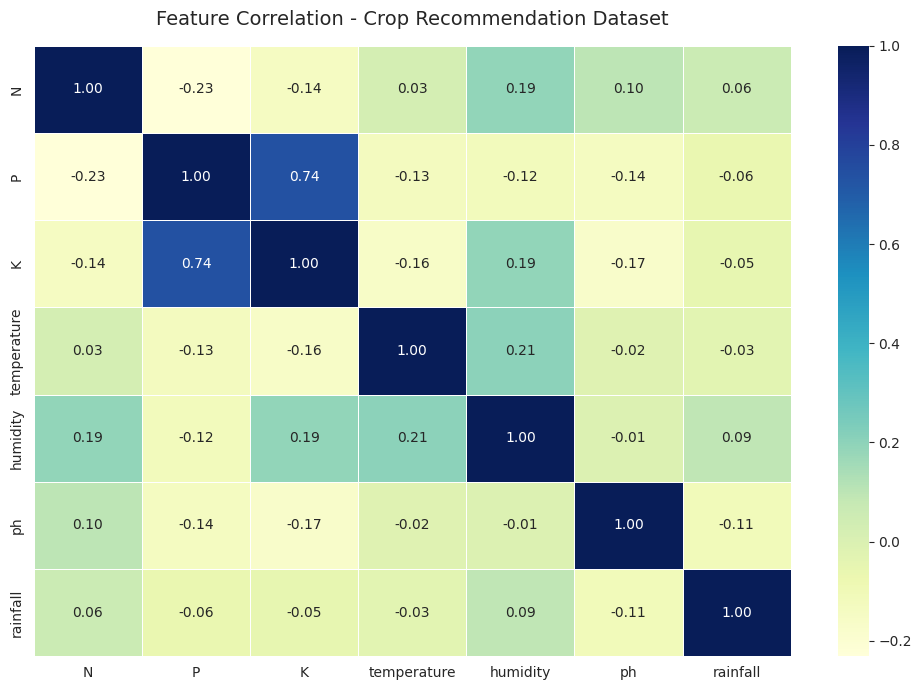

In [41]:
# Correlation Heatmap
plt.figure(figsize=(10, 7))
corr = df_crop.drop(columns=['label']).corr()
sns.heatmap(corr, annot=True, cmap='YlGnBu', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation - Crop Recommendation Dataset', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

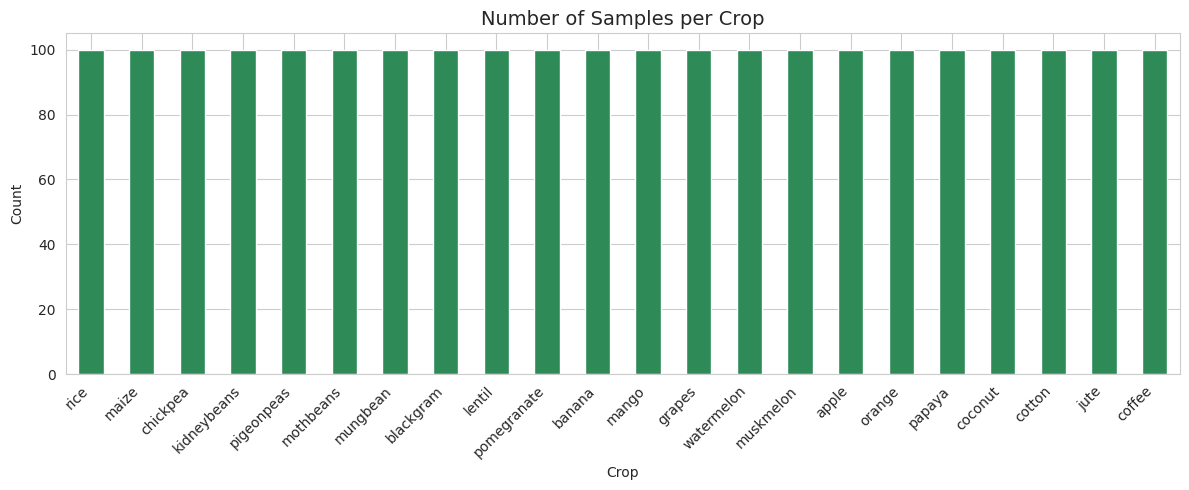

In [42]:
# Distribution of crops
plt.figure(figsize=(12, 5))
df_crop['label'].value_counts().plot(kind='bar', color='seagreen')
plt.title('Number of Samples per Crop', fontsize=14)
plt.xlabel('Crop')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## -> Yield Dataset

In [43]:
# info
df_yield.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2596 entries, 0 to 2595
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Fertilizer  2596 non-null   float64
 1   temp        2596 non-null   float64
 2   N           2596 non-null   float64
 3   P           2596 non-null   float64
 4   K           2596 non-null   float64
 5   yield       2596 non-null   float64
dtypes: float64(6)
memory usage: 121.8 KB


In [44]:
# missing value
df_yield.isnull().sum()

,0
Fertilizer,0
temp,0
N,0
P,0
K,0
yield,0


In [45]:
# Duplicate rows
df_yield.duplicated().sum()

np.int64(11)

In [46]:
# Statistical Summary
df_yield.describe().round(2)

,Fertilizer,temp,N,P,K,yield
count,2596.00,2596.00,2596.00,2596.00,2596.00,2596.00
mean,66.49,33.85,69.52,20.71,17.81,8.53
std,9.75,5.37,6.80,1.97,1.94,1.94
min,49.75,23.77,58.84,17.72,14.70,5.15
25%,59.87,28.00,64.83,18.99,15.98,6.93
50%,65.01,36.97,69.89,20.89,18.06,8.50
75%,76.94,38.93,76.85,22.13,19.13,10.05
max,80.22,40.27,80.22,25.16,22.06,12.34


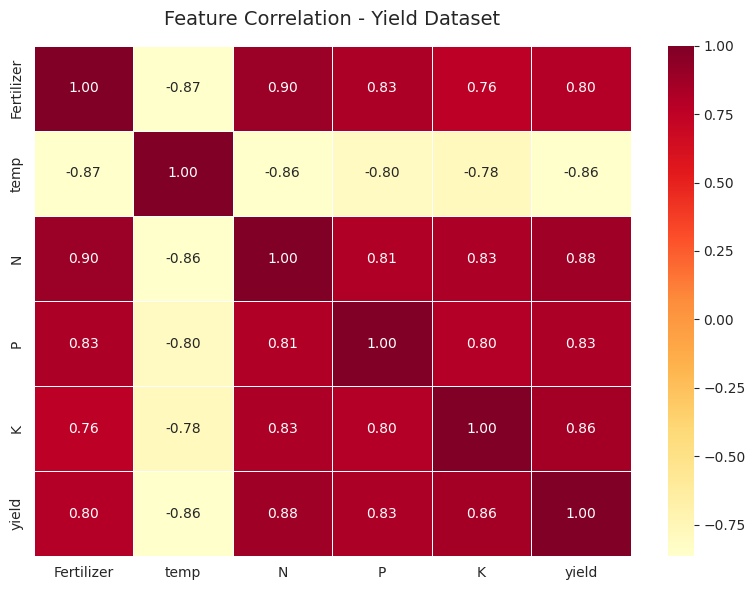

In [47]:
# Correlation Heatmap
plt.figure(figsize=(8, 6))
corr_yield = df_yield.corr()
sns.heatmap(corr_yield, annot=True, cmap='YlOrRd', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation - Yield Dataset', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

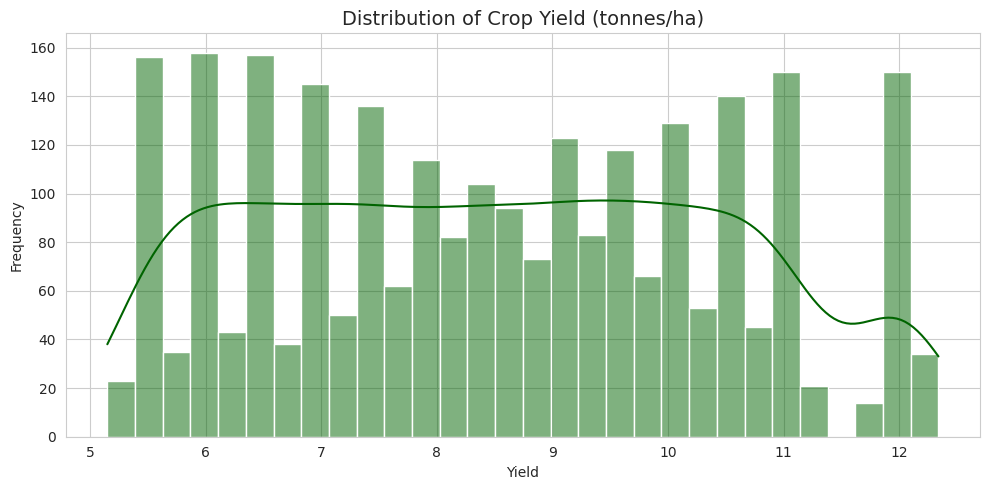

In [48]:
# Yield distribution
plt.figure(figsize=(10, 5))
sns.histplot(df_yield['yield'], bins=30, kde=True, color='darkgreen')
plt.title('Distribution of Crop Yield (tonnes/ha)', fontsize=14)
plt.xlabel('Yield')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

---
# Data Preprocessing

## -> Crop Recommendation (Classification)

In [49]:
# Features & Target
X_crop = df_crop.drop(columns=['label'])
y_crop = df_crop['label']

# Encode labels
le = LabelEncoder()
y_crop_encoded = le.fit_transform(y_crop)

print("Classes:", list(le.classes_))
print("Number of classes:", len(le.classes_))

Classes: ['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']
Number of classes: 22


In [50]:
# Train-Test Split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_crop, y_crop_encoded, test_size=0.2, random_state=42, stratify=y_crop_encoded
)

print(f"Train size: {X_train_c.shape[0]} | Test size: {X_test_c.shape[0]}")

Train size: 1760 | Test size: 440


## -> Yield Prediction (Regression)

In [51]:
# Features & Target
X_yield = df_yield.drop(columns=['yield'])
y_yield = df_yield['yield']

# Train-Test Split
X_train_y, X_test_y, y_train_y, y_test_y = train_test_split(
    X_yield, y_yield, test_size=0.2, random_state=42
)

print(f"Train size: {X_train_y.shape[0]} | Test size: {X_test_y.shape[0]}")

Train size: 2076 | Test size: 520


---
# Model 1: Crop Recommendation (Random Forest Classifier)

In [52]:
# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_c, y_train_c)

# Predictions
y_pred_c = rf_model.predict(X_test_c)

# Evaluation
acc = accuracy_score(y_test_c, y_pred_c)
print(f"Random Forest Accuracy: {acc*100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test_c, y_pred_c, target_names=le.classes_))

Random Forest Accuracy: 99.55%

Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00   

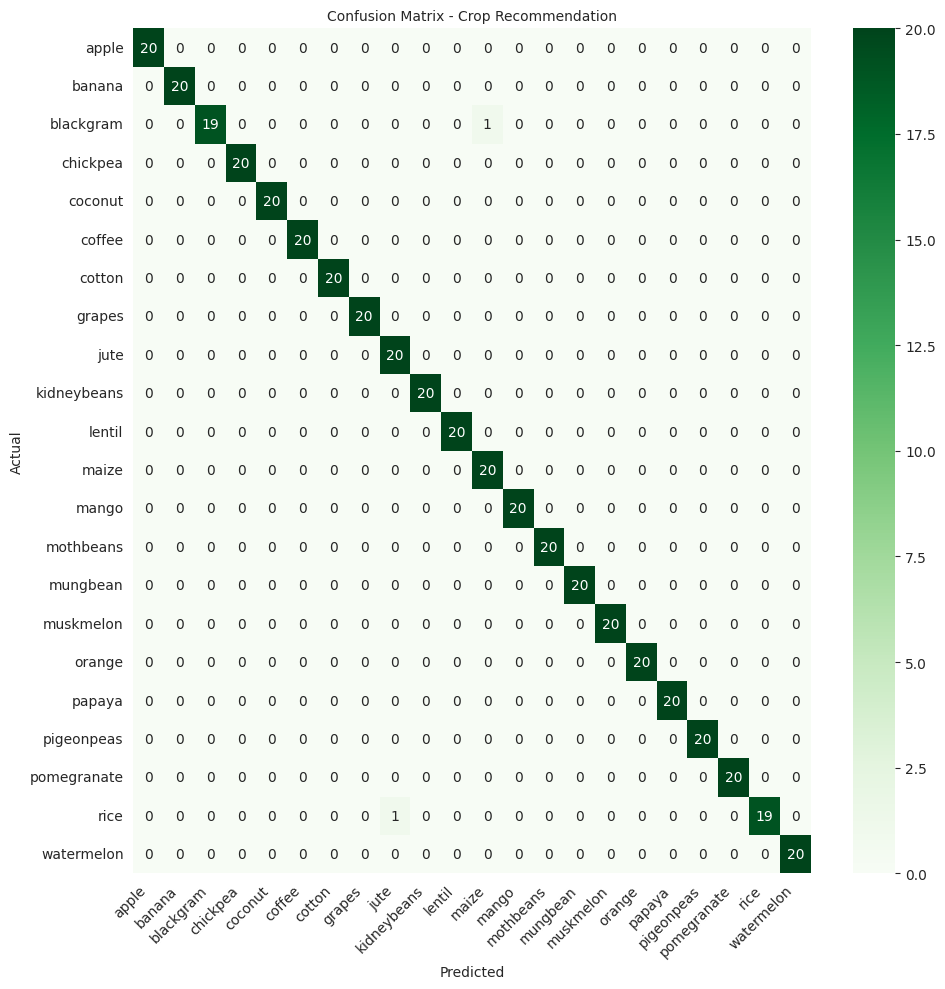

In [53]:
# Confusion Matrix
plt.figure(figsize=(10, 10))
cm = confusion_matrix(y_test_c, y_pred_c)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix - Crop Recommendation', fontsize=10)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

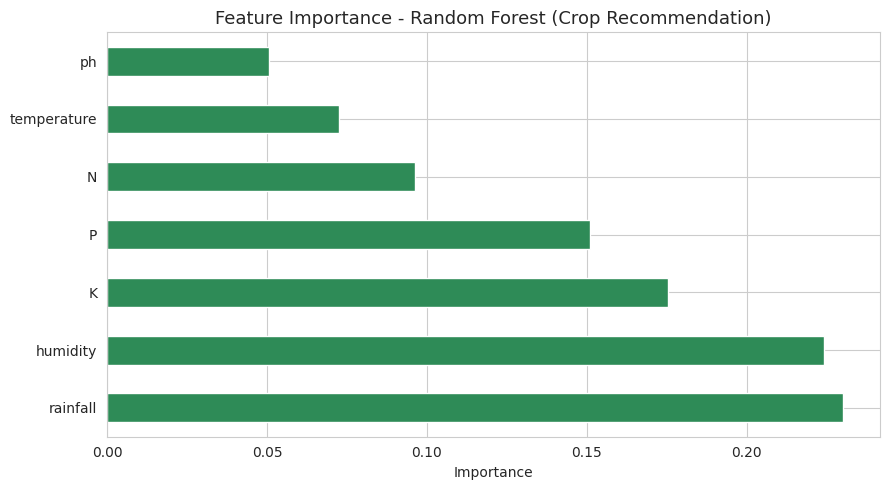

In [54]:
# Feature Importance
feat_imp = pd.Series(rf_model.feature_importances_, index=X_crop.columns).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
feat_imp.plot(kind='barh', color='seagreen')
plt.title('Feature Importance - Random Forest (Crop Recommendation)', fontsize=13)
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

---
# Model 2: Yield Prediction (XGBoost Regressor)

In [55]:
# Train XGBoost
xgb_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_y, y_train_y)

# Predictions
y_pred_y = xgb_model.predict(X_test_y)

# Evaluation
mae = mean_absolute_error(y_test_y, y_pred_y)
rmse = np.sqrt(mean_squared_error(y_test_y, y_pred_y))
r2 = r2_score(y_test_y, y_pred_y)

print(f"XGBoost Results:")
print(f"   MAE  : {mae:.3f}")
print(f"   RMSE : {rmse:.3f}")
print(f"   R²   : {r2:.4f}")

XGBoost Results:
   MAE  : 0.138
   RMSE : 0.212
   R²   : 0.9880


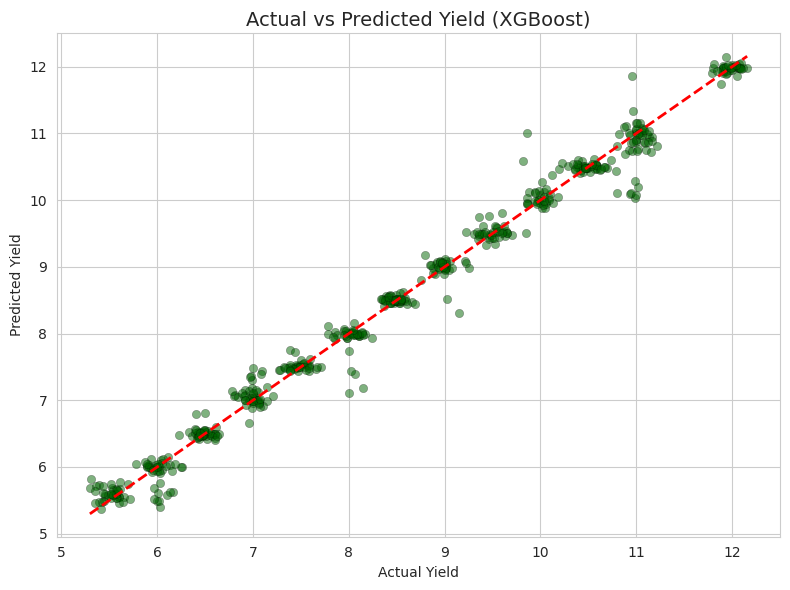

In [56]:
# Actual vs Predicted
plt.figure(figsize=(8, 6))
plt.scatter(y_test_y, y_pred_y, alpha=0.5, color='darkgreen', edgecolors='k', linewidth=0.3)
plt.plot([y_test_y.min(), y_test_y.max()], [y_test_y.min(), y_test_y.max()], 'r--', lw=2)
plt.xlabel('Actual Yield')
plt.ylabel('Predicted Yield')
plt.title('Actual vs Predicted Yield (XGBoost)', fontsize=14)
plt.tight_layout()
plt.show()

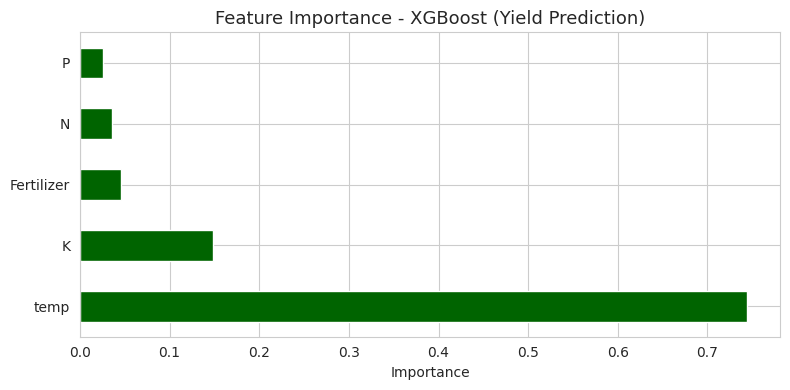

In [57]:
# Feature Importance
feat_imp_xgb = pd.Series(xgb_model.feature_importances_, index=X_yield.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
feat_imp_xgb.plot(kind='barh', color='darkgreen')
plt.title('Feature Importance - XGBoost (Yield Prediction)', fontsize=13)
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

---
# Combined Prediction Function

A single function that:
1. Recommends a crop (Random Forest)
2. Estimates yield (XGBoost)

In [58]:
def smart_advisor(N, P, K, temperature, humidity, ph, rainfall, fertilizer=None):
    """
    Smart Agricultural Advisor

    Parameters
    ----------
    N, P, K, temperature, humidity, ph, rainfall : float
        Soil and weather inputs for crop recommendation.
    fertilizer : float, optional
        Fertilizer amount for yield prediction.
        If None, uses the mean value from the training data.

    Returns
    -------
    recommended_crop : str
    estimated_yield : float (tonnes/ha)
    """
    #  Crop Recommendation
    crop_input = np.array([[N, P, K, temperature, humidity, ph, rainfall]])
    crop_pred_encoded = rf_model.predict(crop_input)[0]
    recommended_crop = le.inverse_transform([crop_pred_encoded])[0]

    #  Yield Prediction
    if fertilizer is None:
        fertilizer = X_yield['Fertilizer'].mean()

    yield_input = np.array([[fertilizer, temperature, N, P, K]])
    estimated_yield = xgb_model.predict(yield_input)[0]

    return recommended_crop, round(float(estimated_yield), 2)


# Test
print("Testing Smart Advisor with sample values:\n")

crop, yield_est = smart_advisor(
    N=90, P=42, K=43,
    temperature=21, humidity=82,
    ph=6.5, rainfall=200
)

print(f"Recommended Crop : {crop}")
print(f"Estimated Yield  : {yield_est} tonnes/ha")

Testing Smart Advisor with sample values:

Recommended Crop : rice
Estimated Yield  : 11.7 tonnes/ha


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
